In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from src.database import get_metrics_as_dataframe, get_system_info

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)

In [2]:
df = get_metrics_as_dataframe()
df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)

print(f"rows: {len(df)}")
print(f"date range: {df['timestamp'].min()} -> {df['timestamp'].max()}")
df.head(3)

rows: 1944
date range: 2026-09-02 19:16:20.102694+00:00 -> 2026-09-21 08:55:24.411951+00:00


,id,timestamp,cpu_percent,cpu_temp,ram_percent,disk_read_mb_s,disk_write_mb_s,disk_usage_percent,net_sent_mb_s,net_recv_mb_s,battery_percent,battery_plugged,gpu_percent,gpu_memory_percent,gpu_temp,top_cpu_1_name,top_cpu_1_percent,top_ram_1_name,top_ram_1_percent,top_cpu_2_name,top_cpu_2_percent,top_ram_2_name,top_ram_2_percent,top_cpu_3_name,top_cpu_3_percent,top_ram_3_name,top_ram_3_percent,system_info_id
0,7,2026-09-02 19:16:20.102694+00:00,11.6,96.0,42.7,NaN,NaN,59.2,NaN,NaN,99.0,1,0.0,2.44,72.0,System,46.7,MsMpEng.exe,1.32,svchost.exe,46.6,nordvpn-service.exe,0.82,MsMpEng.exe,30.7,claude.exe,0.80,1
1,8,2026-09-02 19:16:51.759239+00:00,5.9,78.0,42.3,1.6550,2.4007,59.2,0.0045,0.0080,99.0,1,0.0,2.44,73.0,System,66.1,MsMpEng.exe,1.23,svchost.exe,5.7,nordvpn-service.exe,0.81,dwm.exe,2.9,claude.exe,0.80,1
2,9,2026-09-02 19:17:22.962301+00:00,26.4,98.0,47.3,24.7982,3.6612,59.3,0.0115,0.0201,99.0,1,0.0,2.44,73.0,svchost.exe,121.4,MsMpEng.exe,1.32,System,80.6,explorer.exe,1.08,SignalRgb.exe,69.5,chrome.exe,0.94,1


In [3]:
for row in get_system_info():
    print(dict(row))
    print("=" * 110)

{'id': 1, 'recorded_at': '2026-09-02T18:59:45.466956+00:00', 'hostname': 'Amir', 'os_name': 'Windows', 'os_version': 'Windows-11-10.0.26200-SP0', 'cpu_model': '11th Gen Intel(R) Core(TM) i7-11800H @ 2.30GHz', 'cpu_cores_physical': 8, 'cpu_cores_logical': 16, 'ram_total_gb': 31.79, 'gpu_backend': 'nvidia', 'gpu_names': 'NVIDIA GeForce RTX 3060 Laptop GPU, Intel(R) UHD Graphics', 'is_hybrid_gpu_system': 1, 'python_version': '3.14.7', 'collector_interval_seconds': 30}


cpu_temp           1.70
disk_read_mb_s     1.08
disk_write_mb_s    1.03
net_recv_mb_s      1.03
net_sent_mb_s      1.03
dtype: float64


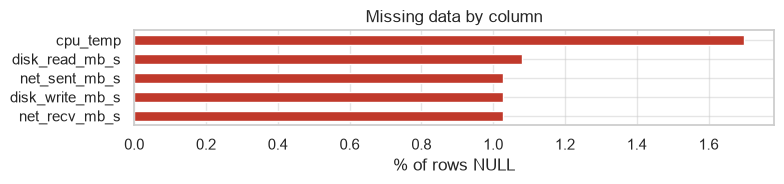

In [4]:
null_rates = (df.isna().mean() * 100).sort_values(ascending=False)
null_rates = null_rates[null_rates > 0]
print(null_rates.round(2))

if len(null_rates):
    fig, ax = plt.subplots(figsize=(8, max(2, 0.3 * len(null_rates))))
    null_rates.sort_values().plot.barh(ax=ax, color="#c0392b")
    ax.set_xlabel("% of rows NULL")
    ax.set_title("Missing data by column")
    plt.tight_layout()
    plt.show()

In [5]:
gaps = df["timestamp"].diff().dt.total_seconds()
SESSION_GAP_THRESHOLD_S = 120

df["session_id"] = (gaps > SESSION_GAP_THRESHOLD_S).cumsum()
print(f"detected sessions: {df['session_id'].nunique()}")
print(gaps[gaps <= SESSION_GAP_THRESHOLD_S].describe().round(2))

session_summary = df.groupby("session_id").agg(
    start=("timestamp", "min"), end=("timestamp", "max"), rows=("timestamp", "count")
)
session_summary["duration"] = session_summary["end"] - session_summary["start"]
session_summary

detected sessions: 20
count    1924.00
mean       31.46
std         2.57
min        31.12
25%        31.15
50%        31.18
75%        31.40
max       109.65
Name: timestamp, dtype: float64


,start,end,rows,duration
session_id,,,,
0,2026-09-02 19:16:20.102694+00:00,2026-09-02 20:03:45.999103+00:00,92,0 days 00:47:25.896409
1,2026-09-03 06:21:15.409012+00:00,2026-09-03 06:50:26.085409+00:00,57,0 days 00:29:10.676397
2,2026-09-03 07:26:24.740287+00:00,2026-09-03 07:42:29.668169+00:00,31,0 days 00:16:04.927882
3,2026-09-03 08:02:16.797645+00:00,2026-09-03 08:24:28.513677+00:00,43,0 days 00:22:11.716032
4,2026-09-03 08:29:41.029634+00:00,2026-09-03 10:25:36.947993+00:00,222,0 days 01:55:55.918359
5,2026-09-03 10:35:58.295835+00:00,2026-09-03 11:31:42.092069+00:00,108,0 days 00:55:43.796234
6,2026-09-03 11:41:56.174465+00:00,2026-09-03 14:13:42.108263+00:00,292,0 days 02:31:45.933798
7,2026-09-03 14:16:02.947939+00:00,2026-09-03 15:12:55.403563+00:00,110,0 days 00:56:52.455624
8,2026-09-03 15:41:24.583310+00:00,2026-09-03 15:47:44.928057+00:00,13,0 days 00:06:20.344747


,cpu_percent,ram_percent,gpu_percent,cpu_temp,gpu_temp
count,1944.00,1944.00,1944.00,1911.00,1944.00
mean,16.11,57.60,2.44,83.96,69.42
std,18.07,5.44,13.97,10.74,5.74
min,1.40,41.70,0.00,52.00,35.00
25%,7.30,54.50,0.00,75.00,68.00
50%,10.90,58.20,0.00,84.00,69.00
75%,16.20,59.90,0.00,95.00,71.00
max,100.00,99.80,100.00,100.00,88.00


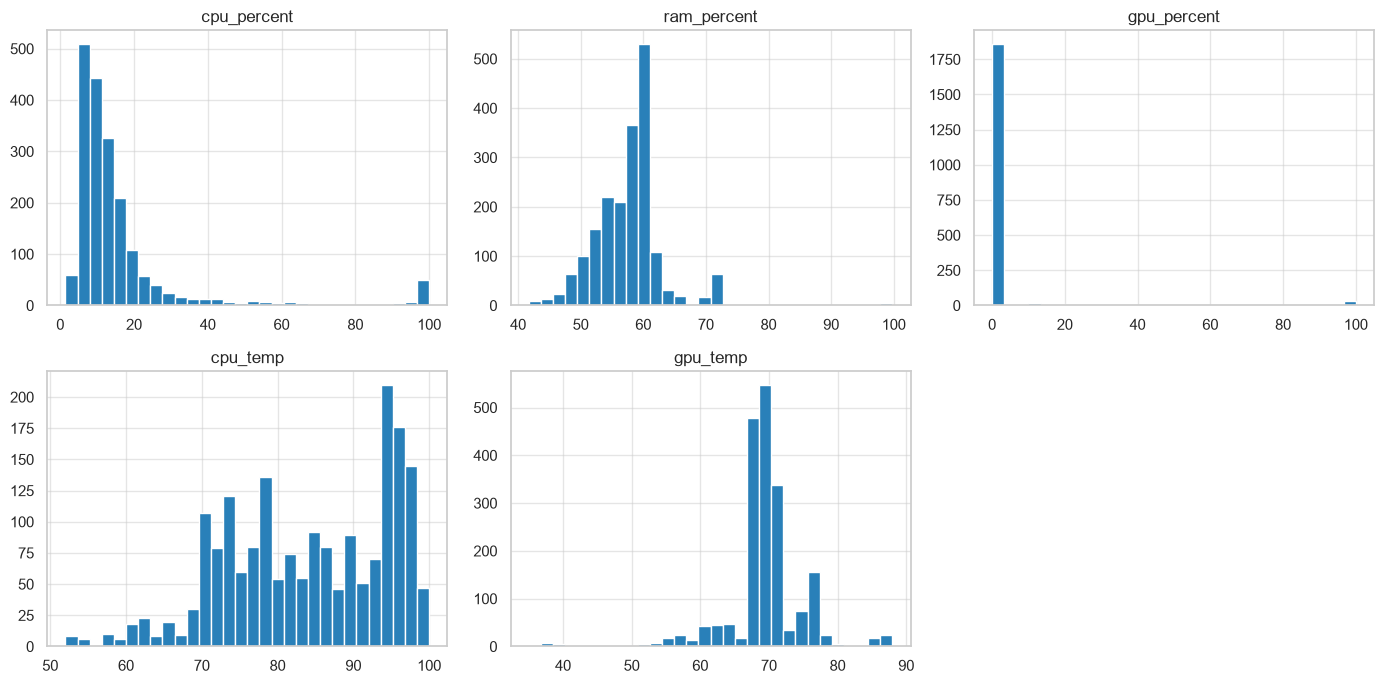

In [6]:
key_metrics = ["cpu_percent", "ram_percent", "gpu_percent", "cpu_temp", "gpu_temp"]
display(df[key_metrics].describe().round(2))

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, key_metrics):
    df[col].dropna().hist(ax=ax, bins=30, color="#2980b9", edgecolor="white")
    ax.set_title(col)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

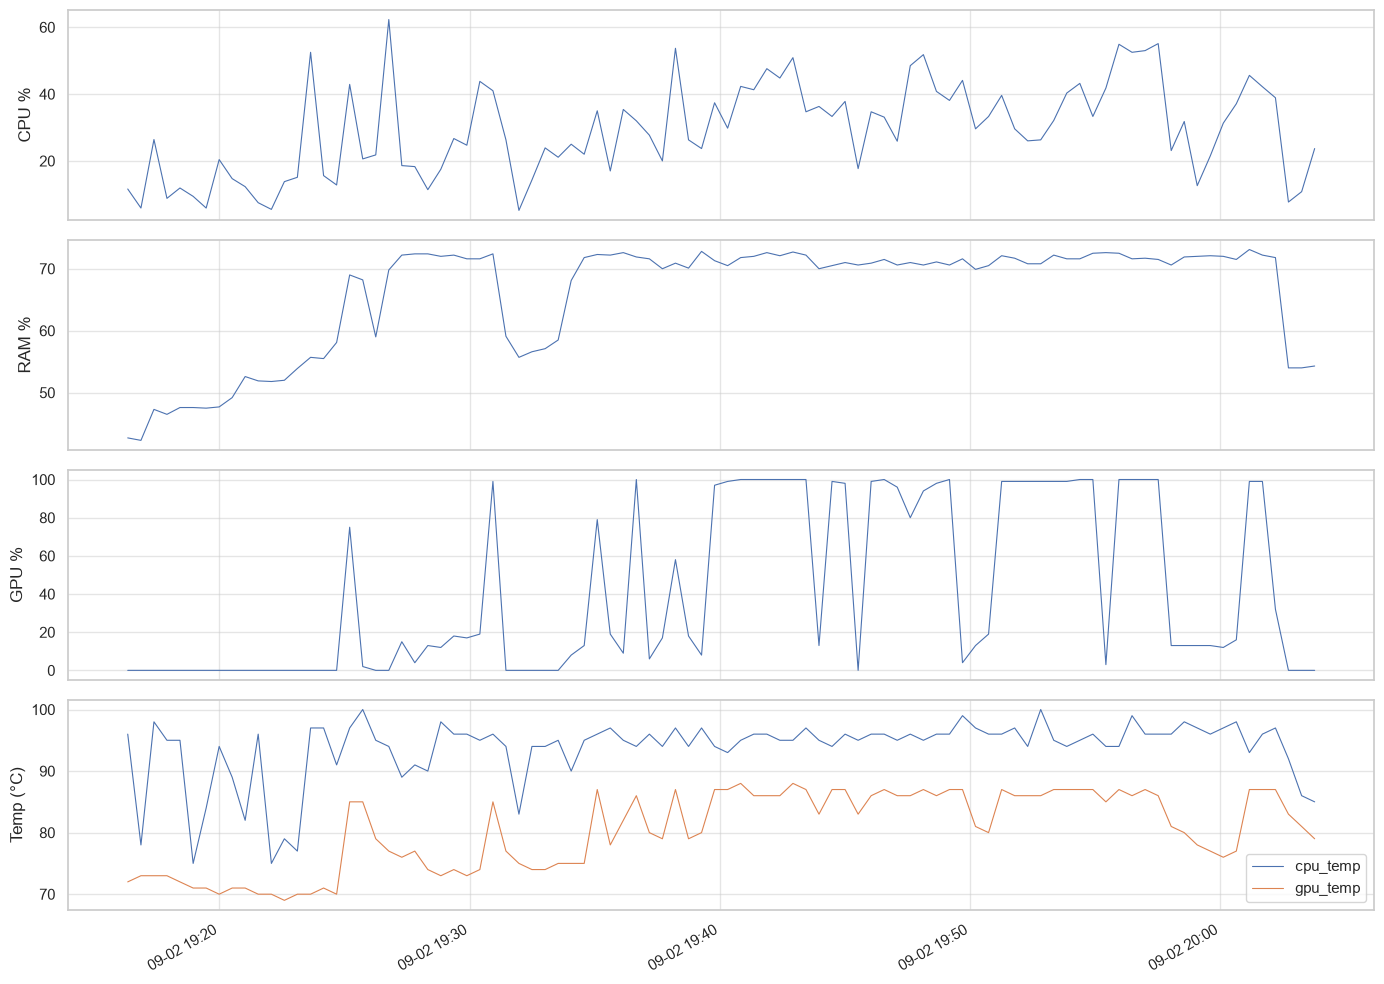

In [7]:
session_id = 0

session_df = df[df["session_id"] == session_id]

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

panels = [
    (["cpu_percent"], "CPU %"),
    (["ram_percent"], "RAM %"),
    (["gpu_percent"], "GPU %"),
    (["cpu_temp", "gpu_temp"], "Temp (°C)")
]

for ax, (cols, label) in zip(axes, panels):
    for col in cols:
        ax.plot(
            session_df["timestamp"],
            session_df[col],
            linewidth=0.8,
            label=col
        )

    ax.set_ylabel(label)

    if len(cols) > 1:
        ax.legend()

axes[-1].xaxis.set_major_formatter(
    mdates.DateFormatter("%m-%d %H:%M")
)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

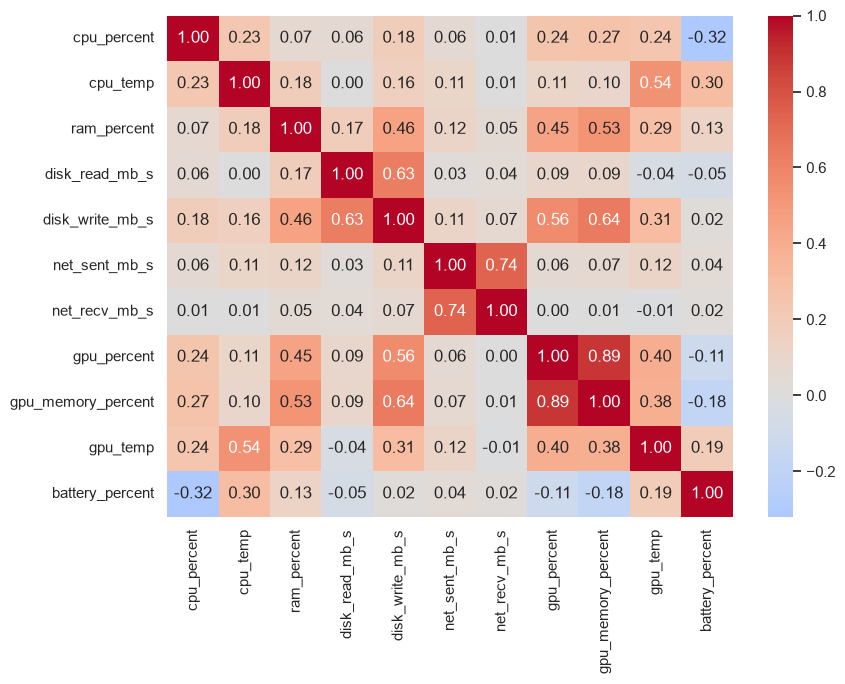

In [8]:
corr_cols = ["cpu_percent", "cpu_temp", "ram_percent", "disk_read_mb_s", "disk_write_mb_s",
             "net_sent_mb_s", "net_recv_mb_s", "gpu_percent", "gpu_memory_percent",
             "gpu_temp", "battery_percent"]

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
plt.tight_layout()
plt.show()

In [9]:
def flag_outliers(series, threshold=3.0):
    z = (series - series.mean()) / series.std()
    return series[z.abs() > threshold]

for col in ["cpu_percent", "ram_percent", "gpu_percent"]:
    outliers = flag_outliers(df.set_index("timestamp")[col].dropna())
    if len(outliers):
        print(f"--- {col}: {len(outliers)} points beyond |z|>3 ---")
        print(outliers.round(2), "\n")

--- cpu_percent: 70 points beyond |z|>3 ---
timestamp
2026-09-03 07:27:34.866837+00:00     81.7
2026-09-03 07:39:47.744530+00:00     71.5
2026-09-03 07:40:20.224814+00:00     82.0
2026-09-03 08:24:28.513677+00:00     82.1
2026-09-03 08:29:41.029634+00:00    100.0
                                    ...  
2026-09-21 08:14:42.465853+00:00     98.6
2026-09-21 08:15:14.740947+00:00     94.5
2026-09-21 08:15:46.362889+00:00     95.1
2026-09-21 08:16:18.202115+00:00     97.1
2026-09-21 08:16:50.842866+00:00     99.8
Name: cpu_percent, Length: 70, dtype: float64 

--- ram_percent: 5 points beyond |z|>3 ---
timestamp
2026-09-03 09:04:19.558486+00:00    99.8
2026-09-03 09:04:51.429166+00:00    98.2
2026-09-03 09:05:22.631568+00:00    98.0
2026-09-03 09:08:00.066504+00:00    99.2
2026-09-03 09:08:32.212405+00:00    98.6
Name: ram_percent, dtype: float64 

--- gpu_percent: 50 points beyond |z|>3 ---
timestamp
2026-09-02 19:25:12.251739+00:00     75.0
2026-09-02 19:30:55.727473+00:00     99.0
2026

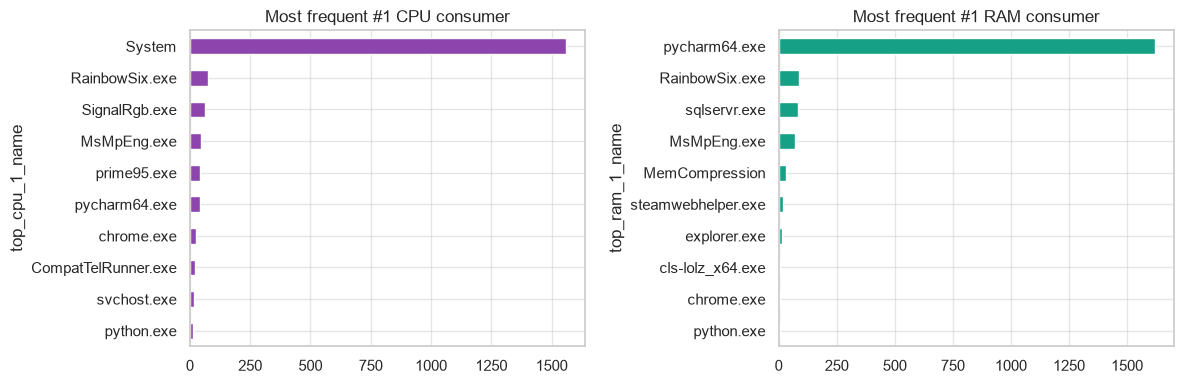

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["top_cpu_1_name"].value_counts().head(10).plot.barh(ax=axes[0], color="#8e44ad")
axes[0].invert_yaxis(); axes[0].set_title("Most frequent #1 CPU consumer")

df["top_ram_1_name"].value_counts().head(10).plot.barh(ax=axes[1], color="#16a085")
axes[1].invert_yaxis(); axes[1].set_title("Most frequent #1 RAM consumer")
plt.tight_layout()
plt.show()